# Assignment 4 starter: human activity recognition from accelerometer data

This notebook loads the data, defines a training and evaluation harness, and trains a 1D CNN baseline. Your job is to add LSTM and Transformer models below the baseline and compare them under the same protocol. The assignment description on Canvas lists the requirements and the grading.

**Before you start:** in Colab, choose *Runtime > Change runtime type > GPU*, then *File > Save a copy in Drive* and work in your copy.

## The data

[UniMiB SHAR](https://www.mdpi.com/2076-3417/7/10/1101) (Micucci, Mobilio and Napoletano, 2017) contains smartphone accelerometer recordings from 30 subjects aged 18 to 60, covering 9 activities of daily living and 8 kinds of falls. We use the 9 activities of daily living. The phone was in a trouser pocket and sampled acceleration at 50 Hz. Each example is a window of 151 samples (about 3 seconds) centered on an acceleration peak above 1.5 g, with four channels: the x, y and z acceleration in m/s² and the magnitude of the acceleration vector.

| Label | Name used here | Activity |
|---|---|---|
| 0 | StandUp | Standing up from sitting |
| 1 | GetUp | Standing up from lying |
| 2 | Walk | Walking |
| 3 | Run | Running |
| 4 | Upstairs | Going upstairs |
| 5 | Jump | Jumping |
| 6 | Downstairs | Going downstairs |
| 7 | LieDown | Lying down from standing |
| 8 | SitDown | Sitting down |

The split is by subject: 18 subjects for training, 6 for validation and 6 for testing. No person appears in more than one split, so the test score measures how well a model works on people it has never seen. The classes are imbalanced (Run has about 13 times as many windows as StandUp), so the headline metric is **macro F1**, the unweighted mean of the nine per-class F1 scores, reported alongside accuracy.

## 1. Setup

In [1]:
import os, time, copy, random, math, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import io
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cpu":
    print("No GPU found. In Colab, use Runtime > Change runtime type > GPU.")


def set_seed(seed):
    """Seed Python, NumPy and PyTorch so that a run can be repeated."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

Using device: cuda


## 2. Data loading

`download_dataset` fetches the dataset archive (266 MB) the first time and unzips it; later calls reuse the local copy. `load_adl` reads the activities-of-daily-living windows and adds the magnitude channel.

In [2]:
DATA_URL = "https://www.dropbox.com/s/raw/x2fpfqj0bpf8ep6/UniMiB-SHAR.zip"

SPLIT = dict(train=[4, 5, 6, 7, 8, 10, 11, 12, 14, 15, 19, 20, 21, 22, 24, 26, 27, 29],
             valid=[1, 9, 16, 23, 25, 28],
             test=[2, 3, 13, 17, 18, 30])

CLASS_NAMES = ["StandUp", "GetUp", "Walk", "Run", "Upstairs", "Jump", "Downstairs", "LieDown", "SitDown"]
N_CLASSES = len(CLASS_NAMES)


def download_dataset(url=DATA_URL, zip_path="UniMiB-SHAR.zip"):
    """Download and unzip UniMiB SHAR unless it is already here."""
    if not os.path.isfile(zip_path):
        print("Downloading", zip_path, "(266 MB) ...")
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(zip_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
    if not os.path.isdir("UniMiB-SHAR"):
        shutil.unpack_archive(zip_path, ".", "zip")


def load_adl(path="UniMiB-SHAR/data"):
    """Return the windows (N, 151, 4), the activity labels (0 to 8) and the subject ids (1 to 30)."""
    data = io.loadmat(f"{path}/adl_data.mat")["adl_data"]        # (N, 453): 151 x values, then 151 y, then 151 z
    labels = io.loadmat(f"{path}/adl_labels.mat")["adl_labels"]  # columns: activity (1 to 9), subject, trial
    x = data.reshape(-1, 151, 3, order="F")                        # (N, 151, 3)
    magnitude = np.sqrt((x ** 2).sum(axis=2, keepdims=True))
    x = np.concatenate([x, magnitude], axis=2).astype(np.float32)  # (N, 151, 4): x, y, z, magnitude
    return x, labels[:, 0].astype(np.int64) - 1, labels[:, 1]


download_dataset()
X_all, y_all, subject = load_adl()
splits = {name: (X_all[np.isin(subject, ids)], y_all[np.isin(subject, ids)]) for name, ids in SPLIT.items()}

counts = pd.DataFrame({name: np.bincount(y, minlength=N_CLASSES) for name, (x, y) in splits.items()}, index=CLASS_NAMES)
counts.loc["total"] = counts.sum()
counts

,train,valid,test
StandUp,96,23,34
GetUp,127,42,47
Walk,1132,262,344
Run,1164,408,413
Upstairs,557,180,184
Jump,448,152,146
Downstairs,782,286,256
LieDown,160,68,68
SitDown,135,33,32
total,4601,1454,1524


One window per class, magnitude channel only. Some pairs look alike even to the eye, which is worth remembering when you read the confusion matrices.

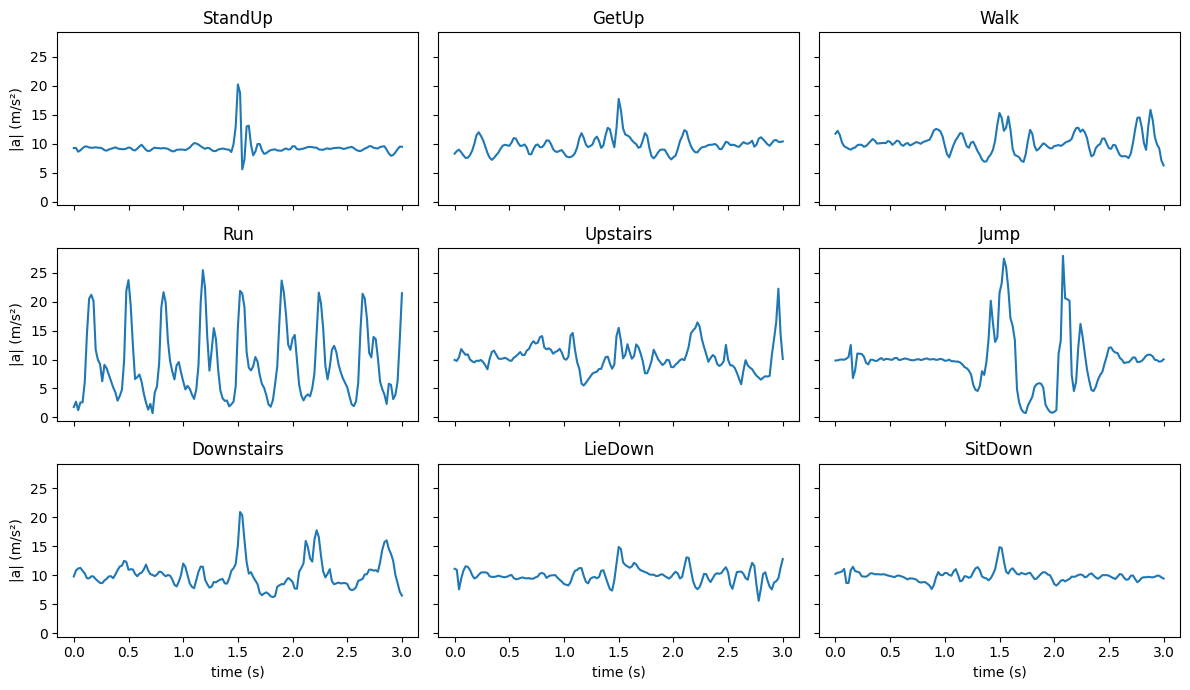

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(12, 7), sharex=True, sharey=True)
t = np.arange(151) / 50  # seconds
x_train, y_train = splits["train"]
for c, ax in enumerate(axes.flat):
    i = np.flatnonzero(y_train == c)[0]
    ax.plot(t, x_train[i, :, 3])
    ax.set_title(CLASS_NAMES[c])
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("|a| (m/s²)")
plt.tight_layout()
plt.show()

### Normalization and data loaders

The y axis carries most of gravity, so the raw channels have very different scales. Each channel is standardized with the mean and standard deviation of the **training set only**; using validation or test statistics would leak information about those subjects into training.

Every loader yields batches shaped **(batch, timesteps, channels) = (64, 151, 4)**. A model that needs a different layout permutes inside its `forward` method, as the CNN below does.

In [4]:
mean = splits["train"][0].mean(axis=(0, 1))
std = splits["train"][0].std(axis=(0, 1))
print("Training-set mean per channel (x, y, z, magnitude):", mean.round(2))
print("Training-set std per channel:                     ", std.round(2))

BATCH_SIZE = 64


def make_loader(x, y, shuffle):
    x = torch.tensor((x - mean) / std, dtype=torch.float32)
    return DataLoader(TensorDataset(x, torch.tensor(y)), batch_size=BATCH_SIZE, shuffle=shuffle)


train_loader = make_loader(*splits["train"], shuffle=True)
valid_loader = make_loader(*splits["valid"], shuffle=False)
test_loader = make_loader(*splits["test"], shuffle=False)

x_batch, y_batch = next(iter(train_loader))
print("One batch:", tuple(x_batch.shape), tuple(y_batch.shape))

Training-set mean per channel (x, y, z, magnitude): [ 0.15  1.86 -0.71 10.05]
Training-set std per channel:                      [4.65 9.05 3.54 4.37]
One batch: (64, 151, 4) (64,)


## 3. Training and evaluation harness

Every model in this assignment is trained and tested with the same protocol, so that differences in the results come from the models:

- AdamW with cosine learning-rate decay and gradient clipping at norm 1.
- After every epoch the model is scored on the validation set, and the weights from the epoch with the best validation macro F1 are kept.
- `run_experiment` repeats this for three seeds and tests each final model once. Different seeds give different initial weights and batch orders, so the spread across seeds shows how much of a difference between two models is noise.
- `results_table()` summarizes every experiment run so far as mean ± standard deviation over seeds.

You may pass `n_epochs`, `lr` and `weight_decay` to `run_experiment` and change anything inside your models. Do not change the split, the normalization or the selection rule. Choose hyperparameters by looking at validation scores (`plot_history`), not test scores.

**Parameter budget.** Every model must have between 100,000 and 200,000 trainable parameters, so that differences in the results come from the architectures rather than from their size. The only exception is Transformer variant A, which is far smaller by design. `run_experiment` prints a note when a model falls outside the budget.

`evaluate` takes an optional `transform`, a function applied to each input batch before the model sees it. You will need it for the shuffle test in Part 2.

In [5]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@torch.no_grad()
def evaluate(model, loader, transform=None):
    """Loss, accuracy, macro F1 and predictions of `model` on `loader`.

    transform: optional function applied to each input batch (batch, timesteps, channels) before the model.
    """
    model.eval()
    losses, y_true, y_pred = [], [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        if transform is not None:
            x = transform(x)
        logits = model(x)
        losses.append(F.cross_entropy(logits, y, reduction="sum").item())
        y_true.append(y.cpu())
        y_pred.append(logits.argmax(dim=1).cpu())
    y_true, y_pred = torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()
    return dict(loss=sum(losses) / len(y_true), acc=accuracy_score(y_true, y_pred),
                macro_f1=f1_score(y_true, y_pred, average="macro"), y_true=y_true, y_pred=y_pred)


def train_model(model, n_epochs=40, lr=1e-3, weight_decay=1e-2, verbose=True):
    """Train `model`; keep the weights from the epoch with the best validation macro F1."""
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
    history = dict(train_loss=[], valid_loss=[], valid_f1=[])
    best_f1, best_state, best_epoch = -1.0, None, 0
    for epoch in range(1, n_epochs + 1):
        model.train()
        losses = []
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            losses.append(loss.item())
        scheduler.step()
        val = evaluate(model, valid_loader)
        history["train_loss"].append(np.mean(losses))
        history["valid_loss"].append(val["loss"])
        history["valid_f1"].append(val["macro_f1"])
        if val["macro_f1"] > best_f1:
            best_f1, best_epoch = val["macro_f1"], epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose and (epoch == 1 or epoch % 5 == 0):
            print(f"epoch {epoch:3d} | train loss {history['train_loss'][-1]:.3f} | "
                  f"valid loss {val['loss']:.3f} | valid macro F1 {val['macro_f1']:.3f}")
    model.load_state_dict(best_state)
    history["best_epoch"], history["best_valid_f1"] = best_epoch, best_f1
    return history


results = {}  # experiment name -> list of runs, one per seed
PARAM_BUDGET = (100_000, 200_000)


def run_experiment(name, make_model, seeds=(0, 1, 2), **train_kwargs):
    """Train a fresh model for each seed, test it, and record the runs under `name`.

    make_model: a function with no arguments that returns a new, untrained model, e.g. lambda: CNN1D().
    train_kwargs: passed on to train_model (n_epochs, lr, weight_decay, verbose).
    """
    train_kwargs.setdefault("verbose", False)
    n_params = count_params(make_model())
    if not PARAM_BUDGET[0] <= n_params <= PARAM_BUDGET[1]:
        print(f"Note: {name} has {n_params:,} trainable parameters, outside the "
              f"{PARAM_BUDGET[0]:,} to {PARAM_BUDGET[1]:,} budget.")
    runs = []
    for seed in seeds:
        set_seed(seed)
        model = make_model()
        start = time.time()
        history = train_model(model, **train_kwargs)
        seconds = time.time() - start
        test = evaluate(model, test_loader)
        print(f"{name} | seed {seed} | best epoch {history['best_epoch']:2d} | "
              f"valid macro F1 {history['best_valid_f1']:.3f} | test acc {test['acc']:.3f} | "
              f"test macro F1 {test['macro_f1']:.3f} | {seconds:.0f} s")
        runs.append(dict(seed=seed, model=model, history=history, test=test, seconds=seconds,
                         params=count_params(model)))
    results[name] = runs
    return runs


def mean_std(values):
    values = np.asarray(values)
    sd = values.std(ddof=1) if len(values) > 1 else 0.0
    return f"{values.mean():.3f} ± {sd:.3f}"


def results_table():
    rows = []
    for name, runs in results.items():
        rows.append({"model": name,
                     "parameters": f"{runs[0]['params']:,}",
                     "test accuracy": mean_std([r["test"]["acc"] for r in runs]),
                     "test macro F1": mean_std([r["test"]["macro_f1"] for r in runs]),
                     "seconds per run": round(np.mean([r["seconds"] for r in runs]))})
    return pd.DataFrame(rows).set_index("model")


def plot_history(run, title=""):
    h = run["history"]
    epochs = np.arange(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    ax1.plot(epochs, h["train_loss"], label="train")
    ax1.plot(epochs, h["valid_loss"], label="validation")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy loss"); ax1.legend()
    ax2.plot(epochs, h["valid_f1"])
    ax2.axvline(h["best_epoch"], color="gray", linestyle="--", label="kept epoch")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("validation macro F1"); ax2.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_confusion(run, title=""):
    t = run["test"]
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(t["y_true"], t["y_pred"], display_labels=CLASS_NAMES,
                                            xticks_rotation=45, colorbar=False, cmap="Blues", ax=ax)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 4. Baseline: a 1D CNN

Two convolution layers slide along the time axis. Max pooling and then an average over the whole time axis (global average pooling) reduce each window to one 100-dimensional vector, and two fully connected layers classify it. Averaging over time keeps the classifier small: it has about 108,000 parameters, inside the budget. `nn.Conv1d` expects **(batch, channels, timesteps)**, so `forward` permutes the input first.

In [6]:
class CNN1D(nn.Module):
    def __init__(self, n_channels=4, n_classes=N_CLASSES,
                 n_filters=100, kernel_size=9, fc_size=128, dropout=0.5):
        super().__init__()
        self.conv1 = nn.Conv1d(n_channels, n_filters, kernel_size, padding="same")
        self.bn1 = nn.BatchNorm1d(n_filters)
        self.conv2 = nn.Conv1d(n_filters, n_filters, kernel_size, padding="same")
        self.bn2 = nn.BatchNorm1d(n_filters)
        self.pool = nn.MaxPool1d(2)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(n_filters, fc_size)
        self.fc2 = nn.Linear(fc_size, n_classes)

    def forward(self, x):          # x: (batch, timesteps, channels)
        x = x.permute(0, 2, 1)     # (batch, channels, timesteps) for Conv1d
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool(x).mean(dim=2)  # global average pooling over time: (batch, n_filters)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)


print(CNN1D())
print(f"Trainable parameters: {count_params(CNN1D()):,}")

CNN1D(
  (conv1): Conv1d(4, 100, kernel_size=(9,), stride=(1,), padding=same)
  (bn1): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv1d(100, 100, kernel_size=(9,), stride=(1,), padding=same)
  (bn2): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=100, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=9, bias=True)
)
Trainable parameters: 108,289


In [7]:
cnn_runs = run_experiment("CNN (baseline)", lambda: CNN1D())
results_table()

CNN (baseline) | seed 0 | best epoch 34 | valid macro F1 0.868 | test acc 0.874 | test macro F1 0.766 | 17 s


CNN (baseline) | seed 1 | best epoch 33 | valid macro F1 0.892 | test acc 0.896 | test macro F1 0.808 | 16 s


CNN (baseline) | seed 2 | best epoch 23 | valid macro F1 0.875 | test acc 0.906 | test macro F1 0.806 | 16 s


,parameters,test accuracy,test macro F1,seconds per run
model,,,,
CNN (baseline),"108,289",0.892 ± 0.016,0.793 ± 0.023,16


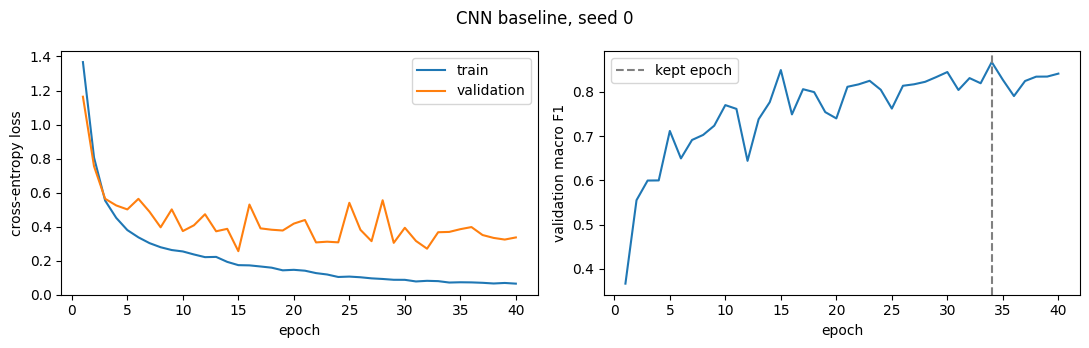

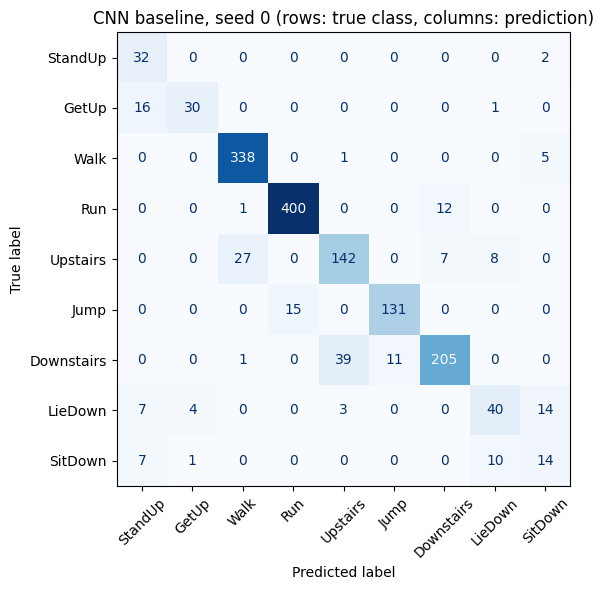

              precision    recall  f1-score   support

     StandUp      0.516     0.941     0.667        34
       GetUp      0.857     0.638     0.732        47
        Walk      0.921     0.983     0.951       344
         Run      0.964     0.969     0.966       413
    Upstairs      0.768     0.772     0.770       184
        Jump      0.923     0.897     0.910       146
  Downstairs      0.915     0.801     0.854       256
     LieDown      0.678     0.588     0.630        68
     SitDown      0.400     0.438     0.418        32

    accuracy                          0.874      1524
   macro avg      0.771     0.781     0.766      1524
weighted avg      0.880     0.874     0.874      1524



In [8]:
plot_history(cnn_runs[0], "CNN baseline, seed 0")
plot_confusion(cnn_runs[0], "CNN baseline, seed 0 (rows: true class, columns: prediction)")
print(classification_report(cnn_runs[0]["test"]["y_true"], cnn_runs[0]["test"]["y_pred"],
                            target_names=CLASS_NAMES, digits=3))

---
# Your work starts here

Add your code and text cells under the headings below. Keep all outputs in the notebook you submit.

## Part 1: LSTM

In [9]:
# Your LSTM model and its run_experiment call

## Part 2: Transformers

### Variant A: no embedding, no positional encoding

In [10]:
# Variant A

### Variant B: convolutional patch embedding, no positional encoding

In [11]:
# Variant B

### Variant C: convolutional patch embedding plus positional encoding

In [12]:
# Variant C

### Shuffle test

In [13]:
# Shuffle test

## Part 3: Comparison and discussion

In [14]:
results_table()

,parameters,test accuracy,test macro F1,seconds per run
model,,,,
CNN (baseline),"108,289",0.892 ± 0.016,0.793 ± 0.023,16


*Your discussion here.*